# IMPORTS

In [326]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import seaborn as sns
from itertools import combinations
import numpy as np

# Mapping tasks to animations

In [354]:

task_mapping = {
    '1.1': 'C011', '1.2': 'C100', '1.3': 'C000', '1.4': 'Cnull', '1.5': 'C100',
    '1.6': 'C110', '1.7': 'C011', '1.8': 'C001', '1.9': 'C111', '2.1': 'B000',
    '2.2': 'Bnull', '2.3': 'B112', '2.4': 'B113', '2.5': 'B012', '2.6': 'B013',
    '2.7': 'B002', '2.8': 'B102', '2.9': 'B103', '3.1': 'A000', '3.2': 'A100',
    '3.3': 'A010', '3.4': 'A101', '3.5': 'A001', '3.6': 'A111', '3.7': 'A110',
    '3.8': 'A011', '3.9': 'Anull'
}

animation_mapping = {
    'A': {
        'type': 'FADE',
        'delay': ['0.3s', '1s'],
        'ease': ['Ease-in', 'Ease-out'],
        'direction': ['Left to Right', 'Top to Bottom'],
    },
    'B': {
        'type': 'BOUNCE',
        'delay': ['0.3s', '1s'],
        'ease': ['Ease-in', 'Ease-out'],
        'direction': {0: 'Left to Right', 1: 'Top to Bottom', 2: 'Bouncing', 3: 'Pulsing'},
    },
    'C': {
        'type': 'SCROLL',
        'delay': ['0.3s', '1s'],
        'ease': ['Ease-in', 'Ease-out'],
        'direction': ['Left to Right', 'Top to Bottom'],
    },
}

In [355]:
def decode_task(task_id) -> dict:
    tid = str(task_id)
    code = task_mapping.get(tid, "")
    if not code:
        return {"type": "Unknown", "delay": None, "ease": None, "direction": None, "code": None}

    family = code[0]
    fam_info = animation_mapping.get(family, {})
    result = {"type": fam_info.get("type", "Unknown"), "delay": None, "ease": None, "direction": None, "code": code}

    # handle null cases like Anull / Bnull / Cnull
    if "null" in code.lower():
        return result

    # extract up to three digit indices after the family letter
    digits = [d for d in code[1:] if d.isdigit()]
    while len(digits) < 3:
        digits.append("0")
    idx_delay, idx_ease, idx_dir = (int(digits[0]), int(digits[1]), int(digits[2]))

    def pick(options, i):
        """options can be list or dict; return None/UNSPEC if not available."""
        if options is None:
            return None
        if isinstance(options, dict):
            return options.get(i, f"UNSPEC({i})")
        if isinstance(options, list):
            return options[i] if 0 <= i < len(options) else f"UNSPEC({i})"
        return None

    result["delay"]     = pick(fam_info.get("delay"),     idx_delay)
    result["ease"]      = pick(fam_info.get("ease"),      idx_ease)
    result["direction"] = pick(fam_info.get("direction"), idx_dir)

    return result

In [356]:
decode_task("2.6")

{'type': 'BOUNCE',
 'delay': '0.3s',
 'ease': 'Ease-out',
 'direction': 'Pulsing',
 'code': 'B013'}

# 1. Attention & processing

## Fixation count

In [329]:
fx_path = "outputs/fixations_within_tasks.csv"
fx = pd.read_csv(fx_path)
fx.head(3)

,Video Name (folder),User ID (file),Source,MEDIA_NAME,TIME,TIMETICK(f=10000000),FPOGX,FPOGY,FPOGS,FPOGD,...,BKDUR,LPMM,LPMMV,RPMM,RPMMV,AOI,SACCADE_MAG,SACCADE_DIR,Unnamed: 21,Task Id
0,P3_S2_ENG,User 0,fixation,S2_Eng,83.30859,189577624597,0.38883,0.83012,83.06250,0.24609,...,0.0,3.92991,1,3.97060,1,NaN,2077.56812,306.19641,NaN,1.1
1,P3_S2_ENG,User 0,fixation,S2_Eng,83.53906,189579925287,0.50433,0.83885,83.32617,0.21289,...,0.0,3.61734,1,3.64544,1,NaN,443.92059,357.56546,NaN,1.1
2,P3_S2_ENG,User 0,fixation,S2_Eng,83.86719,189583211154,0.50997,0.82796,83.55664,0.31055,...,0.0,3.50842,1,3.83258,1,NaN,31.97432,47.36331,NaN,1.1


In [336]:
PARTICIPANT = "P3_S2_ENG" 

fx_p = fx[fx["Video Name (folder)"] == PARTICIPANT].copy()

fx_p = fx_p[(fx_p["Source"] == "fixation") & (fx_p["FPOGV"] == 1)].copy()
fx_p = fx_p.dropna(subset=["FPOGID"])

fx_p.head(3)

,Video Name (folder),User ID (file),Source,MEDIA_NAME,TIME,TIMETICK(f=10000000),FPOGX,FPOGY,FPOGS,FPOGD,...,BKDUR,LPMM,LPMMV,RPMM,RPMMV,AOI,SACCADE_MAG,SACCADE_DIR,Unnamed: 21,Task Id
0,P3_S2_ENG,User 0,fixation,S2_Eng,83.30859,189577624597,0.38883,0.83012,83.06250,0.24609,...,0.0,3.92991,1,3.97060,1,NaN,2077.56812,306.19641,NaN,1.1
1,P3_S2_ENG,User 0,fixation,S2_Eng,83.53906,189579925287,0.50433,0.83885,83.32617,0.21289,...,0.0,3.61734,1,3.64544,1,NaN,443.92059,357.56546,NaN,1.1
2,P3_S2_ENG,User 0,fixation,S2_Eng,83.86719,189583211154,0.50997,0.82796,83.55664,0.31055,...,0.0,3.50842,1,3.83258,1,NaN,31.97432,47.36331,NaN,1.1


In [335]:
# how many unique fixations per task?
fix_count = (
    fx_p.groupby("Task Id")["FPOGID"]
       .nunique()
       .rename("fixation_count")
       .reset_index()
       .sort_values("fixation_count", ascending=False)
)
fix_count.head(3)

,Task Id,fixation_count
3,1.4,160
7,1.8,153
5,1.6,111


# 	Total fixation duration
→ sum of FPOGD within task.

1. Fixation Duration Indicates Cognitive Load

	•	A review published in Frontiers in Computational Neuroscience summarizes foundational work:
“In general, fixation durations are around 200–300 ms… longer fixations indicate deeper cognitive processing” (Rayner, 1978; Salthouse & Ellis, 1980)  .

This is a widely accepted benchmark in eye-tracking research.

2. Cognitive Difficulty Influences Fixations

	•	Experimental research shows that under more difficult viewing conditions (e.g., degraded image quality), mean fixation duration increases as viewers need more time to process visual information  .


3.  Educational Context & Expertise

	•	In a recent systematic review (2025) of eye-tracking studies in education:
“Total fixation duration” and “time spent in area” were among the most-used metrics for examining cognitive processing and learning.  
	•	Expert learners often exhibit longer fixation durations and more transitions, reflecting deeper integration of information (Cheng & Yang, 2022; Wang et al., 2022b)  .

In [337]:
# statistics of fixation durations per task
dur_stats = (
    fx_p.groupby("Task Id")["FPOGD"]
        .agg(
            mean_dur="mean",
            median_dur="median",
            total_dur="sum",
            n_fixations="count"
        )
        .reset_index()
        .sort_values("Task Id")
)

print("Fixation duration statistics per Task Id:")
dur_stats.head(4)


Fixation duration statistics per Task Id:


,Task Id,mean_dur,median_dur,total_dur,n_fixations
0,1.1,0.299340,0.279300,30.83204,103
1,1.2,0.282848,0.263670,9.33397,33
2,1.3,0.309181,0.271485,3.09181,10
3,1.4,0.287268,0.262695,45.96290,160


# Filter result table

In [338]:
# filter tasks function
def analyze_task_group(dur_stats: pd.DataFrame, prefix: str):
    subset = dur_stats[dur_stats["Task Id"].astype(str).str.startswith(prefix)].copy()
    return subset

In [339]:
# Add animation parameters to dur_stats
dur_stats["delay"] = dur_stats["Task Id"].apply(lambda tid: decode_task(tid)["delay"])
dur_stats["ease"] = dur_stats["Task Id"].apply(lambda tid: decode_task(tid)["ease"])
dur_stats["direction"] = dur_stats["Task Id"].apply(lambda tid: decode_task(tid)["direction"])

dur_stats.head(5)

,Task Id,mean_dur,median_dur,total_dur,n_fixations,delay,ease,direction
0,1.1,0.299340,0.279300,30.83204,103,0.1s,Ease-out,Top to Bottom
1,1.2,0.282848,0.263670,9.33397,33,1s,Ease-in,Left to Right
2,1.3,0.309181,0.271485,3.09181,10,0.1s,Ease-in,Left to Right
3,1.4,0.287268,0.262695,45.96290,160,None,None,None
4,1.5,0.260153,0.246090,27.57621,106,1s,Ease-in,Left to Right


# TEXT TASKS

1.	High fixation count + short mean duration

→ The user is scanning quickly, moving their eyes often.
	•	Interpretation: Searching for information, not focusing deeply.
	•	Example: Looking through a map with many small details.
	2.	Low fixation count + long mean duration


→ The user is focusing for longer on fewer points.

	•	Interpretation: Deep processing, maybe reading carefully or analyzing something.
	•	Example: Reading a block of text, or focusing on a list item.
	3.	High fixation count + long duration


→ Both frequent stops and long processing.

	•	Interpretation: The task is demanding or confusing.
	•	Could suggest cognitive overload or inefficient animation design.
	4.	Low fixation count + short duration


→ Minimal scanning and shallow processing.

	•	Interpretation: The task is easy, or the animation makes the solution obvious.

In [340]:
text_tasks = analyze_task_group(dur_stats, prefix="1.")
text_tasks

,Task Id,mean_dur,median_dur,total_dur,n_fixations,delay,ease,direction
0,1.1,0.299340,0.279300,30.83204,103,0.1s,Ease-out,Top to Bottom
1,1.2,0.282848,0.263670,9.33397,33,1s,Ease-in,Left to Right
2,1.3,0.309181,0.271485,3.09181,10,0.1s,Ease-in,Left to Right
3,1.4,0.287268,0.262695,45.96290,160,None,None,None
4,1.5,0.260153,0.246090,27.57621,106,1s,Ease-in,Left to Right
5,1.6,0.270288,0.246090,30.00201,111,1s,Ease-out,Left to Right
6,1.7,0.259695,0.246090,28.56643,110,0.1s,Ease-out,Top to Bottom
7,1.8,0.264898,0.246090,40.52938,153,0.1s,Ease-in,Top to Bottom
8,1.9,0.258970,0.246090,13.98437,54,1s,Ease-out,Top to Bottom


In [341]:
tt = text_tasks.copy()

# cols are numeric
num_cols = ["mean_dur","median_dur","total_dur","n_fixations"]
for c in num_cols:
    tt[c] = pd.to_numeric(tt[c], errors="coerce")

# replace None with string for grouping
for c in ["delay","ease","direction"]:
    tt[c] = tt[c].fillna("None").astype(str)

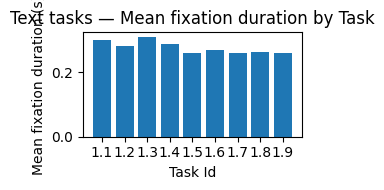

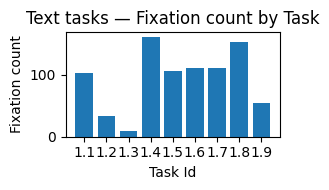

In [342]:
# Mean fixation duration by Task Id
plt.figure(figsize=(3, 2))
plt.bar(tt["Task Id"].astype(str), tt["mean_dur"])
plt.title("Text tasks — Mean fixation duration by Task")
plt.xlabel("Task Id")
plt.ylabel("Mean fixation duration (s)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Fixation count by Task Id
plt.figure(figsize=(3, 2))
plt.bar(tt["Task Id"].astype(str), tt["n_fixations"])
plt.title("Text tasks — Fixation count by Task")
plt.xlabel("Task Id")
plt.ylabel("Fixation count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Mean fixations duration for delay, ease and direction:
![Screenshot 2025-09-11 at 3.44.49 PM.png](<attachment:Screenshot 2025-09-11 at 3.44.49 PM.png>)

another idea is to see for each parameter stats: ease, duration...
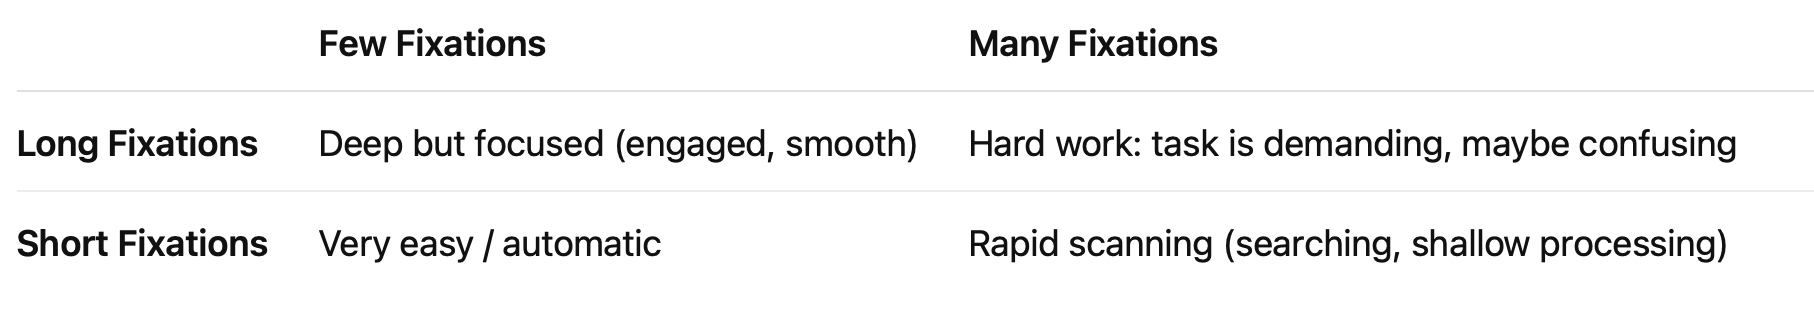

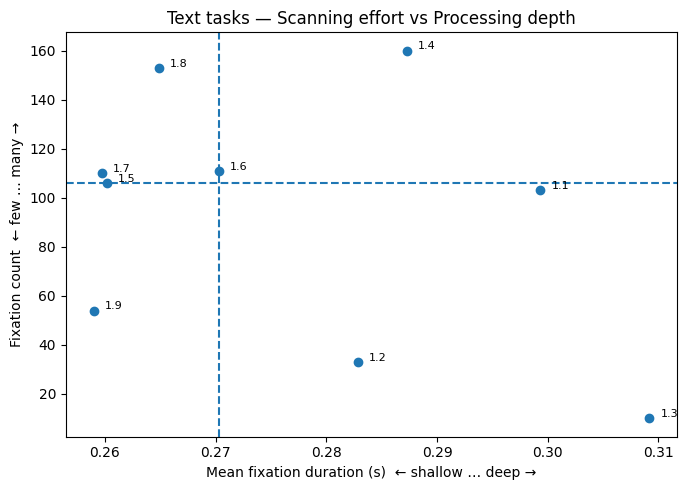

In [343]:
x_med = tt["mean_dur"].median()
y_med = tt["n_fixations"].median()

plt.figure(figsize=(7,5))
plt.scatter(tt["mean_dur"], tt["n_fixations"])

for _, r in tt.iterrows():
    plt.text(r["mean_dur"]+0.001, r["n_fixations"]+0.5, str(r["Task Id"]), fontsize=8)

plt.axvline(x_med, linestyle="--")
plt.axhline(y_med, linestyle="--")

plt.title("Text tasks — Scanning effort vs Processing depth")
plt.xlabel("Mean fixation duration (s)  ← shallow … deep →")
plt.ylabel("Fixation count  ← few … many →")
plt.tight_layout()
plt.show()

# Spatial attention for bounce tasks


In [344]:
# Keep only Bounce tasks
bounce_fx = fx[fx["Task Id"].astype(str).str.startswith("2.")].copy()

print("Bounce task rows:", bounce_fx.shape)
bounce_fx.head()

Bounce task rows: (173, 26)


,Video Name (folder),User ID (file),Source,MEDIA_NAME,TIME,TIMETICK(f=10000000),FPOGX,FPOGY,FPOGS,FPOGD,...,BKDUR,LPMM,LPMMV,RPMM,RPMMV,AOI,SACCADE_MAG,SACCADE_DIR,Unnamed: 21,Task Id
161,P3_S2_ENG,User 0,fixation,S2_Eng,647.07227,195215252524,0.04565,0.48788,646.75977,0.31250,...,0.0,3.64012,1,3.84194,1,P3_LIST-P3_ALL,51.92790,352.92758,NaN,2.3
162,P3_S2_ENG,User 0,fixation,S2_Eng,647.54883,195220016580,0.01706,0.48803,647.08984,0.45898,...,0.0,3.82633,1,3.85754,1,P3_LIST-P3_ALL,109.78608,180.16908,NaN,2.3
163,P3_S2_ENG,User 0,fixation,S2_Eng,647.84375,195222975833,0.08682,0.46229,647.56445,0.27930,...,0.0,3.67543,1,3.84512,1,P3_LIST-P3_ALL,273.58728,11.72532,NaN,2.3
164,P3_S2_ENG,User 0,fixation,S2_Eng,648.05859,195225111429,0.09824,0.60000,647.86133,0.19727,...,0.0,4.40276,1,4.03610,1,P3_LIST-P3_ALL,300.66879,278.38654,NaN,2.3
165,P3_S2_ENG,User 0,fixation,S2_Eng,648.45312,195229053724,0.08993,0.78220,648.12305,0.33008,...,0.0,4.56780,1,3.97364,1,P3_LIST-P3_ALL,394.84357,265.36441,NaN,2.3


In [345]:
def classify_region(x, y):
    if pd.isna(x) or pd.isna(y):
        return "Unknown"
    return "Left" if x < 0.5 else "Right"

bounce_fx["region"] = bounce_fx.apply(lambda r: classify_region(r["FPOGX"], r["FPOGY"]), axis=1)

In [346]:
region_stats = (
    bounce_fx.groupby(["Task Id","region"])["FPOGD"]
    .sum()
    .reset_index()
    .pivot(index="Task Id", columns="region", values="FPOGD")
    .fillna(0)
)

# Compute total & percentages
region_stats["TotalDur"] = region_stats.sum(axis=1)
region_stats["Pct_Left"] = (region_stats["Left"] / region_stats["TotalDur"]) * 100
region_stats["Pct_Right"] = (region_stats["Right"] / region_stats["TotalDur"]) * 100

region_stats.reset_index(inplace=True)
region_stats

region,Task Id,Left,Right,TotalDur,Pct_Left,Pct_Right
0,2.1,6.74610,0.88672,7.63282,88.382800,11.617200
1,2.2,4.87502,4.10743,8.98245,54.272721,45.727279
2,2.3,4.04493,6.43946,10.48439,38.580499,61.419501
3,2.4,4.56838,0.50781,5.07619,89.996237,10.003763
4,2.5,8.74807,0.00000,8.74807,100.000000,0.000000
5,2.6,1.93751,0.00000,1.93751,100.000000,0.000000
6,2.7,5.13867,0.27734,5.41601,94.879256,5.120744
7,2.8,6.38281,0.31250,6.69531,95.332554,4.667446
8,2.9,2.12110,0.44336,2.56446,82.711370,17.288630


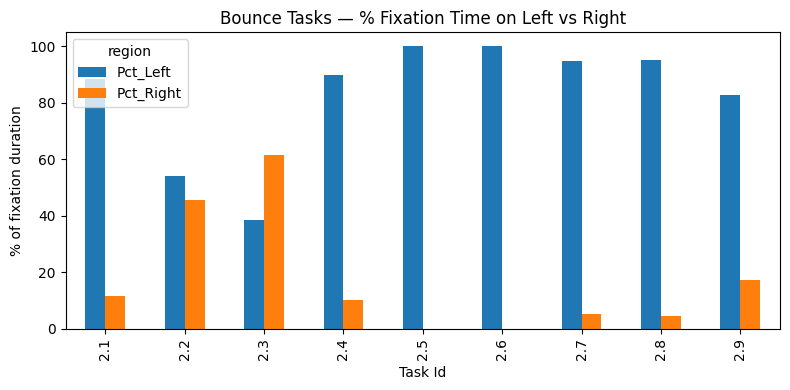

In [347]:
region_stats.plot(
    x="Task Id",
    y=["Pct_Left","Pct_Right"],
    kind="bar",
    figsize=(8,4),
    title="Bounce Tasks — % Fixation Time on Left vs Right"
)
plt.ylabel("% of fixation duration")
plt.xlabel("Task Id")
plt.tight_layout()
plt.show()

# Cluster analysis using K-means

one idea on a possible analysis is to compare clusters across conditions and see how attention is divided

## analysis for scroll tasks


In [350]:
text_fx = fx[fx["Task Id"].astype(str).str.startswith("2.")].copy()

print("Bounce task rows:", bounce_fx.shape)
text_fx.head()

Bounce task rows: (173, 27)


,Video Name (folder),User ID (file),Source,MEDIA_NAME,TIME,TIMETICK(f=10000000),FPOGX,FPOGY,FPOGS,FPOGD,...,BKDUR,LPMM,LPMMV,RPMM,RPMMV,AOI,SACCADE_MAG,SACCADE_DIR,Unnamed: 21,Task Id
161,P3_S2_ENG,User 0,fixation,S2_Eng,647.07227,195215252524,0.04565,0.48788,646.75977,0.31250,...,0.0,3.64012,1,3.84194,1,P3_LIST-P3_ALL,51.92790,352.92758,NaN,2.3
162,P3_S2_ENG,User 0,fixation,S2_Eng,647.54883,195220016580,0.01706,0.48803,647.08984,0.45898,...,0.0,3.82633,1,3.85754,1,P3_LIST-P3_ALL,109.78608,180.16908,NaN,2.3
163,P3_S2_ENG,User 0,fixation,S2_Eng,647.84375,195222975833,0.08682,0.46229,647.56445,0.27930,...,0.0,3.67543,1,3.84512,1,P3_LIST-P3_ALL,273.58728,11.72532,NaN,2.3
164,P3_S2_ENG,User 0,fixation,S2_Eng,648.05859,195225111429,0.09824,0.60000,647.86133,0.19727,...,0.0,4.40276,1,4.03610,1,P3_LIST-P3_ALL,300.66879,278.38654,NaN,2.3
165,P3_S2_ENG,User 0,fixation,S2_Eng,648.45312,195229053724,0.08993,0.78220,648.12305,0.33008,...,0.0,4.56780,1,3.97364,1,P3_LIST-P3_ALL,394.84357,265.36441,NaN,2.3


In [351]:
def dispersion_metrics(df):
    xs, ys = df["FPOGX"].dropna().values, df["FPOGY"].dropna().values
    if len(xs) == 0:
        return pd.Series({"var_x": np.nan, "var_y": np.nan,
                          "bbox_area": np.nan, "mean_dist": np.nan})

    # Variance
    var_x, var_y = np.var(xs), np.var(ys)

    # Bounding box area
    bbox_area = (xs.max() - xs.min()) * (ys.max() - ys.min())

    # Mean pairwise distance (Euclidean)
    if len(xs) > 1:
        dists = [np.sqrt((x1-x2)**2 + (y1-y2)**2) for (x1,y1),(x2,y2) in combinations(zip(xs,ys), 2)]
        mean_dist = np.mean(dists)
    else:
        mean_dist = 0.0

    return pd.Series({"var_x": var_x, "var_y": var_y,
                      "bbox_area": bbox_area, "mean_dist": mean_dist})

# --- 4) Apply per Task ---
dispersion_stats = text_fx.groupby("Task Id").apply(dispersion_metrics).reset_index()

print("Spatial dispersion metrics per text task:")
print(dispersion_stats.head())

Spatial dispersion metrics per text task:
   Task Id     var_x     var_y  bbox_area  mean_dist
0      2.1  0.055462  0.114201   0.955337   0.491196
1      2.2  0.107197  0.027828   0.536178   0.454434
2      2.3  0.093123  0.039457   0.685412   0.463086
3      2.4  0.046937  0.055724   0.658751   0.394000
4      2.5  0.001627  0.033609   0.116230   0.215828


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_23361/3928072270.py:24: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  dispersion_stats = text_fx.groupby("Task Id").apply(dispersion_metrics).reset_index()


In [352]:
def plot_fixation_heatmap_for_task(df_task: pd.DataFrame, task_id, bins=60):
    """
    Draw a duration-weighted heatmap of fixation positions for one Task Id.
    Each call creates a single figure (as required).
    """
    if df_task.empty:
        print(f"No data for Task {task_id}")
        return

    # Build duration-weighted 2D histogram
    H, xedges, yedges = np.histogram2d(
        df_task["FPOGX"].values,
        df_task["FPOGY"].values,
        bins=bins,
        range=[[0.0, 1.0], [0.0, 1.0]],
        weights=df_task["FPOGD"].values
    )

    # Normalize to percent of total fixation time (optional but nice)
    total = H.sum()
    if total > 0:
        H = (H / total) * 100.0

    plt.figure(figsize=(6,5))
    # transpose so X→horizontal, Y→vertical; origin lower to keep (0,0) at bottom-left
    plt.imshow(H.T, origin="lower",
               extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
               aspect="equal")
    cb = plt.colorbar()
    cb.set_label("% of fixation time")

    # Screen-space guides
    plt.title(f"Text Task {task_id} — Fixation Heatmap (duration-weighted)")
    plt.xlabel("X (0 = Left  …  1 = Right)")
    plt.ylabel("Y (0 = Top   …  1 = Bottom)")

    # Optional midlines for quick left/right & top/bottom reading
    plt.axvline(0.5, linestyle="--", linewidth=0.8)
    plt.axhline(0.5, linestyle="--", linewidth=0.8)

    plt.tight_layout()
    plt.show()

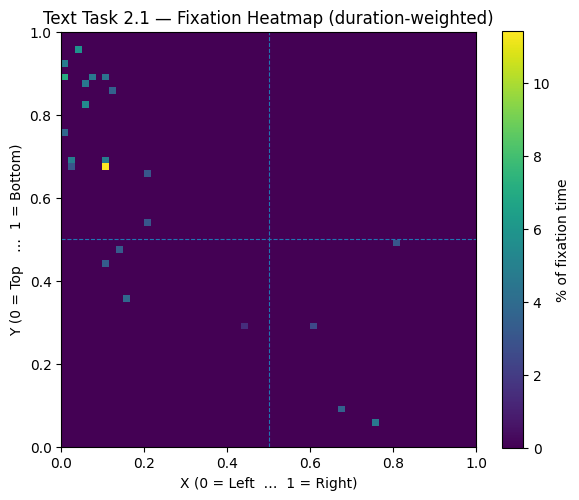

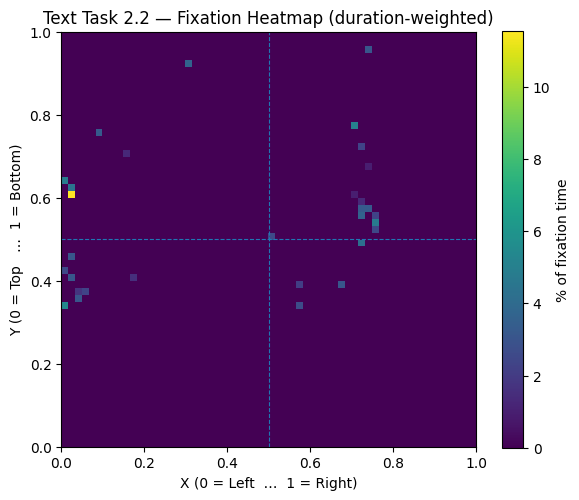

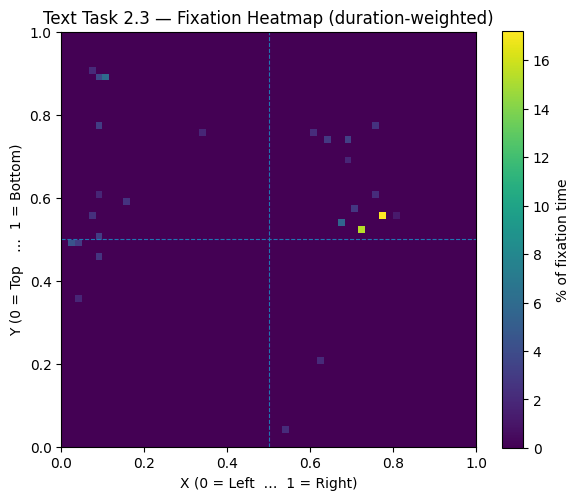

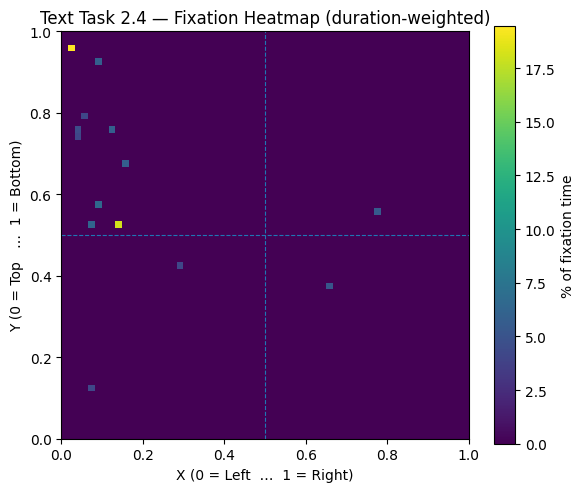

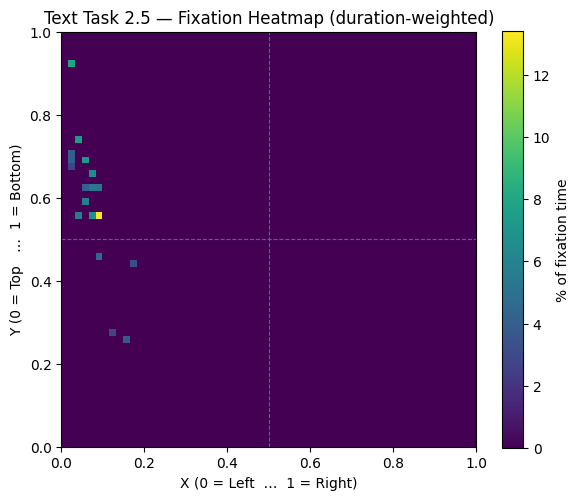

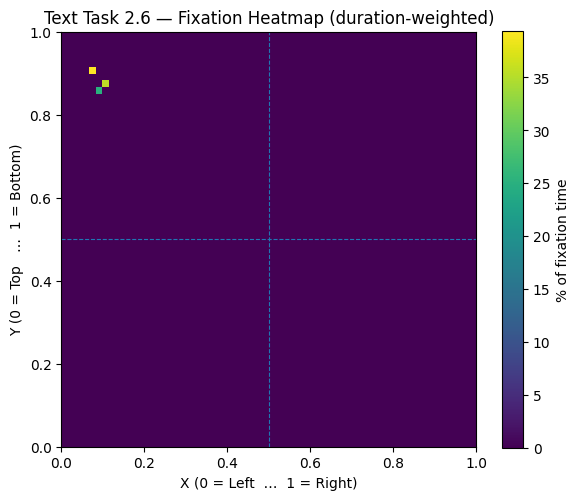

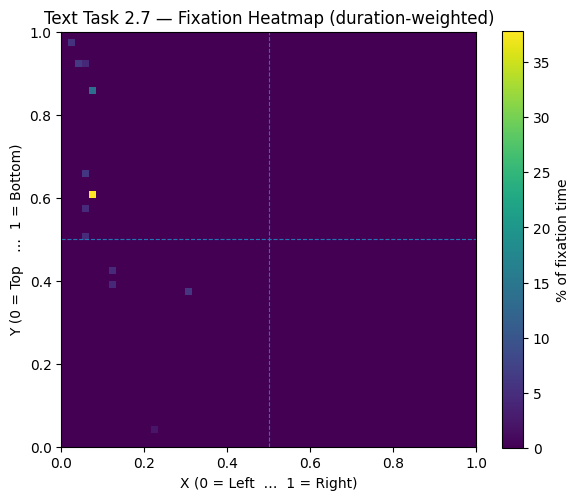

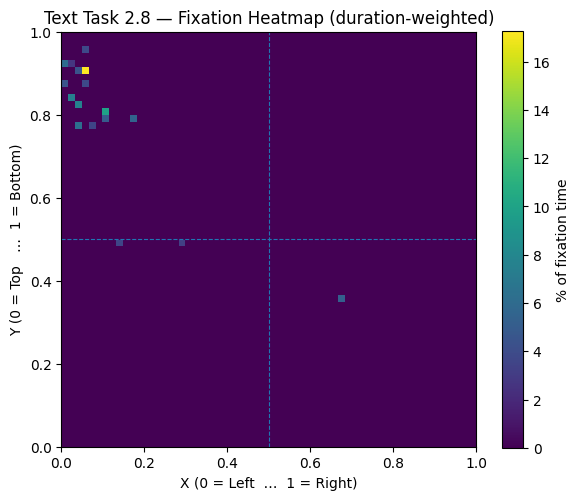

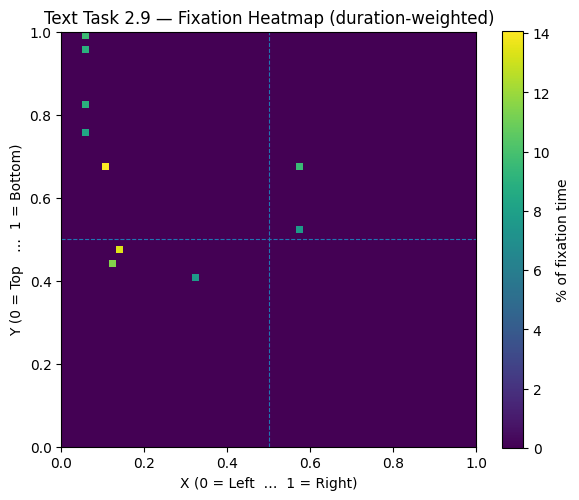

In [353]:
for tid in sorted(text_fx["Task Id"].unique(), key=lambda s: tuple(map(float, str(s).split(".")))):
    df_task = text_fx[text_fx["Task Id"] == tid]
    plot_fixation_heatmap_for_task(df_task, tid, bins=60)

# 3. Blink & fatigue


Higher blink rates → signs of fatigue, overload, reduced visual attention.

Lower blink rates → signs of deep concentration or cognitive load (people often suppress blinking when focusing).

In [318]:
fx_p = fx_p.copy()
fx_p.head(3)

,Video Name (folder),User ID (file),Source,MEDIA_NAME,TIME,TIMETICK(f=10000000),FPOGX,FPOGY,FPOGS,FPOGD,...,BKDUR,LPMM,LPMMV,RPMM,RPMMV,AOI,SACCADE_MAG,SACCADE_DIR,Unnamed: 21,Task Id
0,P3_S2_ENG,User 0,fixation,S2_Eng,83.30859,189577624597,0.38883,0.83012,83.06250,0.24609,...,0.0,3.92991,1,3.97060,1,NaN,2077.56812,306.19641,NaN,1.1
1,P3_S2_ENG,User 0,fixation,S2_Eng,83.53906,189579925287,0.50433,0.83885,83.32617,0.21289,...,0.0,3.61734,1,3.64544,1,NaN,443.92059,357.56546,NaN,1.1
2,P3_S2_ENG,User 0,fixation,S2_Eng,83.86719,189583211154,0.50997,0.82796,83.55664,0.31055,...,0.0,3.50842,1,3.83258,1,NaN,31.97432,47.36331,NaN,1.1


In [319]:
times_path = "/Users/ferolahima/Desktop/gazepoint_project/Export-Video Mappings.xlsx - Foglio1.csv"
tasks_all = pd.read_csv(times_path, sep=None, engine="python")
dur_lookup = tasks_all[["Video Name","User ID","Task Id","Duration in seconds"]].copy()
dur_lookup["Duration in seconds"] = pd.to_numeric(dur_lookup["Duration in seconds"], errors="coerce")
print(dur_lookup.head())

  Video Name User ID  Task Id  Duration in seconds
0  P3_S2_ENG  User 0      1.1                   48
1  P3_S2_ENG  User 0      3.3                   27
2  P3_S2_ENG  User 0      2.3                   12
3  P3_S2_ENG  User 0      1.2                   11
4  P3_S2_ENG  User 0      3.1                    3


In [320]:
fx["BKID"] = pd.to_numeric(fx.get("BKID"), errors="coerce")

group_cols = ["Video Name (folder)", "User ID (file)", "Task Id"]

def blink_stats(g):
    n_blinks = g.loc[g["BKID"] > 0, "BKID"].nunique(dropna=True)
    return pd.Series({"n_blinks": n_blinks})

blink_tasks = fx.groupby(group_cols, dropna=False).apply(blink_stats).reset_index()

# Align columns to merge
blink_tasks = blink_tasks.rename(columns={
    "Video Name (folder)": "Video Name",
    "User ID (file)": "User ID"
})

# Merge task durations
blink_tasks = blink_tasks.merge(
    dur_lookup[["Video Name","User ID","Task Id","Duration in seconds"]],
    on=["Video Name","User ID","Task Id"],
    how="left"
)

# Normalize
blink_tasks = blink_tasks.rename(columns={"Duration in seconds":"task_duration"})
blink_tasks["blinks_per_min"] = (blink_tasks["n_blinks"] / blink_tasks["task_duration"]) * 60

#study only texts
# Keep only Task Ids that start with "1."
blink_text = blink_tasks[blink_tasks["Task Id"].astype(str).str.startswith("1.")].copy()

print(blink_text.head(10))

   Video Name User ID  Task Id  n_blinks  task_duration  blinks_per_min
0   P3_S2_ENG  User 0      1.1         2             48        2.500000
1   P3_S2_ENG  User 0      1.2         1             11        5.454545
2   P3_S2_ENG  User 0      1.5         6             41        8.780488
7   P3_S2_ENG  User 1      1.3         0              5        0.000000
8   P3_S2_ENG  User 1      1.4         3             55        3.272727
9   P3_S2_ENG  User 1      1.6         4             36        6.666667
10  P3_S2_ENG  User 1      1.7         0             34        0.000000
11  P3_S2_ENG  User 1      1.8         5             50        6.000000
20  P3_S2_ENG  User 2      1.9         3             18       10.000000


/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_23361/3426390822.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  blink_tasks = fx.groupby(group_cols, dropna=False).apply(blink_stats).reset_index()


In [321]:
blink_text["delay"]     = blink_text["Task Id"].astype(str).apply(lambda t: decode_task(t)["delay"])
blink_text["ease"]      = blink_text["Task Id"].astype(str).apply(lambda t: decode_task(t)["ease"])
blink_text["direction"] = blink_text["Task Id"].astype(str).apply(lambda t: decode_task(t)["direction"])

do an anova for this kind of analysis, to see how each element contributes seperately

In [322]:
def compare_param(df, param):
    return (df.groupby(param, dropna=False)
               .agg(
                   tasks=("blinks_per_min","count"),
                   blinks_per_min_mean=("blinks_per_min","mean"),
               )
               .sort_values("blinks_per_min_mean", ascending=False)
           )

print("By Delay:\n", compare_param(blink_text, "delay"), "\n")
print("By Ease:\n", compare_param(blink_text, "ease"), "\n")
print("By Direction:\n", compare_param(blink_text, "direction"))

By Delay:
        tasks  blinks_per_min_mean
delay                            
1s         4             7.725425
NaN        1             3.272727
0.1s       4             2.125000 

By Ease:
           tasks  blinks_per_min_mean
ease                                
Ease-in       4             5.058758
Ease-out      4             4.791667
NaN           1             3.272727 

By Direction:
                tasks  blinks_per_min_mean
direction                                
Left to Right      4             5.225425
Top to Bottom      4             4.625000
NaN                1             3.272727


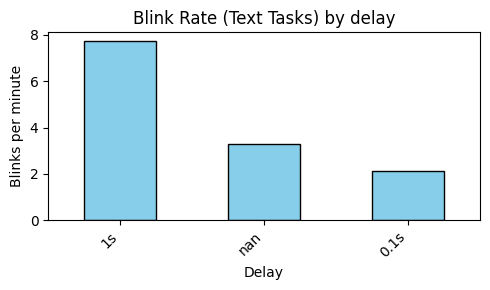

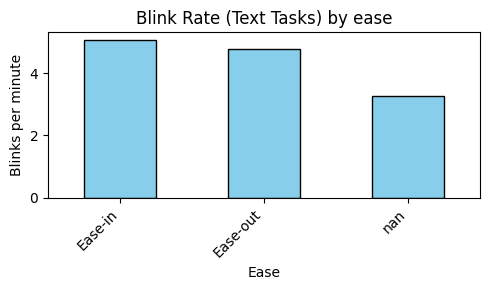

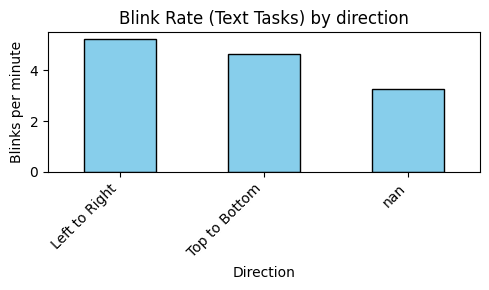

In [283]:
def bar_param(df, param, title):
    s = (df.groupby(param, dropna=False)["blinks_per_min"]
           .mean()
           .sort_values(ascending=False))
    
    plt.figure(figsize=(5,3))
    s.plot(kind="bar", color="skyblue", edgecolor="black")
    plt.title(f"{title} by {param}")
    plt.ylabel("Blinks per minute")
    plt.xlabel(param.capitalize())
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# Run for text tasks
bar_param(blink_text, "delay", "Blink Rate (Text Tasks)")
bar_param(blink_text, "ease", "Blink Rate (Text Tasks)")
bar_param(blink_text, "direction", "Blink Rate (Text Tasks)")

# 4. Pupil dilation

Why not interpret together some parameters:

	•	If you see large pupil peaks + more/larger saccades + suppressed blinks, that task/animation likely triggered excitement.

In [365]:
# Work only with tasks that start with 1.
pupil_text = fx_p[fx_p["Task Id"].astype(str).str.startswith("1.")].copy()

# Make sure pupil size is numeric
pupil_text["LPMM"] = pd.to_numeric(pupil_text["LPMM"], errors="coerce")
pupil_text["RPMM"] = pd.to_numeric(pupil_text["RPMM"], errors="coerce")

# Compute average pupil size (both eyes)
pupil_text["pupil_mm"] = pupil_text[["LPMM","RPMM"]].mean(axis=1)

In [366]:
pupil_stats = (
    pupil_text.groupby("Task Id")["pupil_mm"]
    .agg(
        mean_pupil="mean",
        median_pupil="median",
        max_pupil="max",
        min_pupil="min",
        std_pupil="std",
        n_samples="count"
    )
    .reset_index()
)

print(pupil_stats.head())

   Task Id  mean_pupil  median_pupil  max_pupil  min_pupil  std_pupil  \
0      1.1    4.201502      4.081480    8.16096   3.383215   0.690347   
1      1.2    4.218862      4.231195    5.12152   3.480525   0.438228   
2      1.3    4.041523      3.802985    5.31297   3.211905   0.641767   
3      1.4    4.063903      4.022398    5.55940   3.102805   0.438813   
4      1.5    4.120761      4.098258    5.67410   3.334690   0.451535   

   n_samples  
0        103  
1         33  
2         10  
3        160  
4        106  


<Figure size 800x400 with 0 Axes>

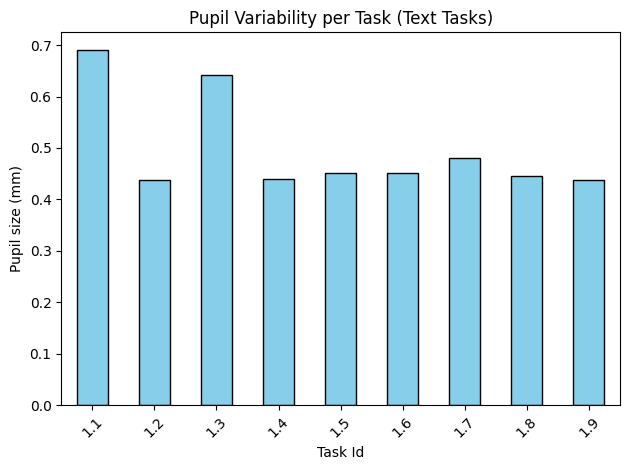

In [367]:
def plot_pupil_extremes(df, value, title):
    plt.figure(figsize=(8,4))
    df.plot(x="Task Id", y=value, kind="bar", legend=False, color="skyblue", edgecolor="black")
    plt.title(title)
    plt.ylabel("Pupil size (mm)")
    plt.xlabel("Task Id")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
plot_pupil_extremes(pupil_stats, "std_pupil", "Pupil Variability per Task (Text Tasks)")

# 5. Saccade


If most saccades are aligned with animation direction → the animation guides visual flow.

If saccades go opposite to animation → animation may be distracting or conflicting with natural reading/scanning.

Bigger magnitudes may mean the eyes are “chasing” the animation, while smaller ones suggest more local, detail-oriented scanning.

In [467]:
gz_path = "outputs/gaze_within_tasks.csv"
gz = pd.read_csv(gz_path)

PARTICIPANT = "P3_S2_ENG" 
gz_p = gz[gz["Video Name (folder)"] == PARTICIPANT].copy()
gz_p = gz_p.dropna(subset=["Task Id"]).copy()
gz_saccades = gz_p[gz_p["SACCADE_DIR"].notna()].copy()
# Drop rows where saccade magnitude is 0 or NaN
gz_p = gz_p[(gz_p["SACCADE_MAG"] > 0) & gz_p["SACCADE_MAG"].notna()].copy()
# Ensure Task Id is always string without spaces
gz_p["Task Id"] = gz_p["Task Id"].astype(str).str.strip()

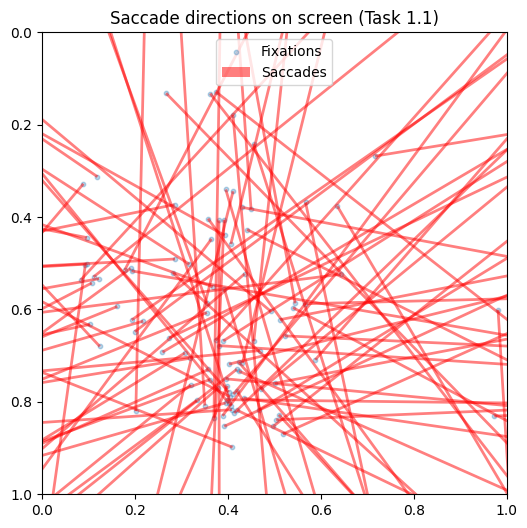

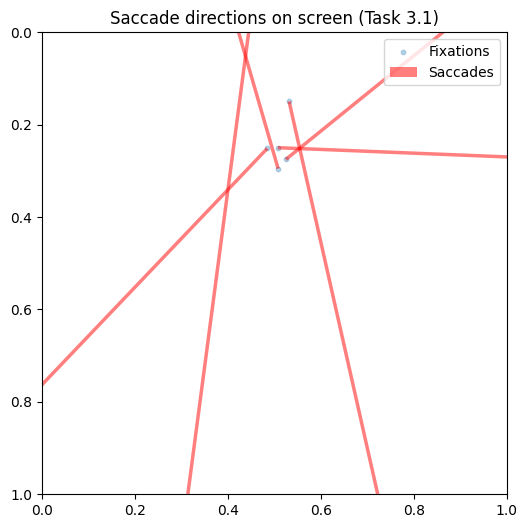

In [469]:
import numpy as np
import matplotlib.pyplot as plt

def plot_task_saccades(gz_df, task_id):
    """
    Visualize fixations + saccades for a given task.
    
    gz_df   : your gaze dataframe (already filtered to one participant if you want)
    task_id : string like "1.1" or "2.5"
    """
    task_df = gz_df[gz_df["Task Id"].astype(str).str.strip() == str(task_id)].copy()
    if task_df.empty:
        print(f"No data found for Task {task_id}")
        return
    
    plt.figure(figsize=(6,6))
    
    # Fixations as dots
    plt.scatter(task_df["FPOGX"], task_df["FPOGY"], 
                alpha=0.3, s=10, label="Fixations")
    
    # Saccade vectors
    plt.quiver(task_df["FPOGX"], task_df["FPOGY"],
               np.cos(np.deg2rad(task_df["SACCADE_DIR"])),
               np.sin(np.deg2rad(task_df["SACCADE_DIR"])),
               angles='xy', scale_units='xy', scale=0.05,
               alpha=0.5, color="red", label="Saccades")
    
    # Screen bounds
    plt.xlim(0,1)
    plt.ylim(0,1)
    plt.gca().invert_yaxis()  # match screen coords
    
    plt.legend()
    plt.title(f"Saccade directions on screen (Task {task_id})")
    plt.show()

# Example usage:
plot_task_saccades(gz_p, "1.1")
plot_task_saccades(gz_p, "3.1")